**Bankrupycy Prediction In Tiwan Using Logistic Regression, Random Forest and Gradient Boosting Models**
This task focuses on the prediction of the dept to classify if it is bankrupt or not using 3 classification models:
1. Logistic Regression
2. Random Forest Classifier
3. Gradient Boosting Classifier
------
The task includes:
1. JSON data extraction and transformation
2. Divide the models into training and testing set
3. Training models and comparing the performance metrices

**Step 0: Importing Libraries**

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import json
from __future__ import annotations
import gzip
from pathlib import Path
from typing import Any
import pickle
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_curve,
roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, precision_recall_curve)
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from imblearn.over_sampling import RandomOverSampler

**Step 1: JSON data extraction and transformation**

In [2]:
#Identifying the paths of the data required to the project 
data_dir = Path('data_required')
paths = sorted(data_dir.glob("*.json*"))
paths

[WindowsPath('data_required/taiwan-bankruptcy-data-test-features.json.gz'),
 WindowsPath('data_required/taiwan-bankruptcy-data.json.gz')]

The file contains 2 JSON files, one is the original and another contains the features of the data

In [3]:
#Loading JSON data
def load_json(path):
    """
    This function contains loading JSON data whether is an ordinary JSON file or compressed to gzip file 
    Input: Path -> the path of the data
    Returns the loaded JSON data
    """
    p = Path(path)
    if p.suffix == ".gz":
        with gzip.open(p, "rt", encoding = "utf-8") as f: #Reading binary file with encoding of UTF-8
            return json.load(f)
    with p.open("r", encoding = "utf-8") as f: #Reading the file
        return json.load(f)

In [4]:
#Defining the payload for this project 
payload = load_json(paths[0])
print(list(payload.keys()))

['schema', 'metadata', 'observations']


In [5]:
#Receiving a payload records and returning list of directories
def extract_records(payload):
    """
    This function extracts payload records and returns list of directories
    Input: payload: Payload records
    Return records: List of directories
    """
    if not isinstance(payload, dict):
        raise TypeError('Payloads must to be dict')
    if 'data' in payload:
        records = payload['data']
    elif 'observations' in payload:
        records = payload['observations']
    else: 
        raise KeyError(f"Could not find these keys --> Keys found: {list(payload.keys())}")
    if not isinstance(records, list):
        raise TypeError("Records must be list")
    if records and not isinstance(records[0], dict):
        raise TypeError("First element must be dict")
    return records

In [6]:
#Check for records
records = extract_records(payload)
records

[{'id': 18,
  'feat_1': 0.5359528104,
  'feat_2': 0.5904382904,
  'feat_3': 0.5809197495,
  'feat_4': 0.6184508281,
  'feat_5': 0.6184508281,
  'feat_6': 0.9991188369,
  'feat_7': 0.7975882553,
  'feat_8': 0.8094607382,
  'feat_9': 0.3035586056,
  'feat_10': 0.7817266065,
  'feat_11': 0.0002487341,
  'feat_12': 0.0,
  'feat_13': 0.4700619847,
  'feat_14': 0.0006370637,
  'feat_15': 0.2174309141,
  'feat_16': 0.1895411066,
  'feat_17': 0.1895411066,
  'feat_18': 0.1895411066,
  'feat_19': 0.2330528505,
  'feat_20': 0.3231590861,
  'feat_21': 0.0257573695,
  'feat_22': 0.1141600847,
  'feat_23': 0.1892746855,
  'feat_24': 0.0221117286,
  'feat_25': 0.848079849,
  'feat_26': 0.6895482861,
  'feat_27': 0.6895482861,
  'feat_28': 0.2176140481,
  'feat_29': 6960000000.0,
  'feat_30': 0.0004717626,
  'feat_31': 0.264260127,
  'feat_32': 0.3811985395,
  'feat_33': 0.0161565799,
  'feat_34': 0.0073831516,
  'feat_35': 0.631059506,
  'feat_36': 0.0033239406,
  'feat_37': 0.0787253983,
  'feat_38

In [7]:
#Convering records to dataframe
def records_to_frame(records):
    """
    This function focuses on turning the records into DataFrame
    Input: records: records extracted from the previous function (extract_records)
    Return: DataFrame of these records
    """
    has_nested = any(isinstance(v, (dict, list)) for r in records for v in r.values())
    if has_nested: 
        return pd.json_normalize(records)
    return pd.DataFrame.from_records(records)

In [8]:
df_records = records_to_frame(records)
df_records

,id,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,feat_94,feat_95
0,18,0.535953,0.590438,0.580920,0.618451,0.618451,0.999119,0.797588,0.809461,0.303559,...,0.826642,0.002746,0.623825,0.618452,0.841983,0.277190,0.026908,0.565659,1,0.048822
1,20,0.487398,0.543720,0.533647,0.636259,0.636252,0.999042,0.797444,0.809340,0.303467,...,0.802552,0.001521,0.623763,0.636256,0.840456,0.277139,0.026924,0.565722,1,0.049622
2,24,0.494857,0.548136,0.540446,0.609507,0.609507,0.999052,0.797413,0.809323,0.303392,...,0.798104,0.018753,0.623486,0.609508,0.840326,0.287134,0.029364,0.568730,1,0.018005
3,32,0.476088,0.544483,0.529686,0.618869,0.618869,0.999014,0.797380,0.809307,0.303415,...,0.796023,0.015252,0.623562,0.618864,0.840052,0.290365,0.174091,0.570161,1,0.016404
4,38,0.478916,0.541321,0.529311,0.607042,0.607006,0.999017,0.797404,0.809317,0.303449,...,0.797744,0.007308,0.623731,0.607042,0.840206,0.281335,0.028426,0.568219,1,0.024781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
677,6802,0.543948,0.606738,0.590021,0.620346,0.620346,0.999176,0.797681,0.809546,0.303600,...,0.836314,0.001398,0.624129,0.620343,0.842457,0.276694,0.026793,0.565166,1,0.058338
678,6805,0.478672,0.544701,0.530703,0.600744,0.600744,0.999006,0.797423,0.809344,0.303506,...,0.804195,0.003066,0.623762,0.600740,0.840497,0.276053,0.026791,0.565159,1,0.080805
679,6813,0.491639,0.549498,0.537877,0.613219,0.613168,0.998999,0.797436,0.809344,0.303543,...,0.806743,0.000548,0.623743,0.613219,0.840676,0.276560,0.026811,0.565253,1,0.061753
680,6814,0.477600,0.531127,0.526099,0.595829,0.595858,0.998905,0.797375,0.809294,0.303634,...,0.794028,0.003475,0.623398,0.595827,0.839864,0.281325,0.022309,0.571752,1,0.024803


In [9]:
#Normalizing columns
def normalize_columns(columns):
    """
    Function of normalizing columns
    Input: columns: columns of dataframe
    Returns: out: normalized columns
    """
    out = []
    for c in columns: 
        c = str(c) #Converting to string
        c = c.strip() #Removing whitespace
        c = c.lower() #Lowercasing
        c = c.replace(" ", "_") #Replacing the empty space to underscore
        c = c.replace("-", "_") #Replacing the score to underscore
        #Checking for alphanumeric characters
        c = "".join(ch for ch in c if c.isalnum() or ch == "_")
        while "__" in c:
            c = c.replace("__", "_")
        out.append(c)
    return out

In [10]:
print(normalize_columns([str(c) for c in df_records.columns]))

['id', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_', '_']


In [11]:
#Cleaning financials to optain the final dataset 
def clean_financials(df):
    """
    Function of cleaning the dataset using normalizing columns and converting to numerical columns
    input: df: the extracted records dataset
    output: df2: the final dataset
    """
    df2 = df.copy()
    df2.columns = normalize_columns([str(c) for c in df2.columns]) 
    df2 = df2.apply(pd.to_numeric, errors='coerce')
    return df2

In [12]:
#Defining the final dataset
final_dataset = clean_financials(df_records)
final_dataset

,id,_,_,_,_,_,_,_,_,_,...,_,_,_,_,_,_,_,_,_,_
0,18,0.535953,0.590438,0.580920,0.618451,0.618451,0.999119,0.797588,0.809461,0.303559,...,0.826642,0.002746,0.623825,0.618452,0.841983,0.277190,0.026908,0.565659,1,0.048822
1,20,0.487398,0.543720,0.533647,0.636259,0.636252,0.999042,0.797444,0.809340,0.303467,...,0.802552,0.001521,0.623763,0.636256,0.840456,0.277139,0.026924,0.565722,1,0.049622
2,24,0.494857,0.548136,0.540446,0.609507,0.609507,0.999052,0.797413,0.809323,0.303392,...,0.798104,0.018753,0.623486,0.609508,0.840326,0.287134,0.029364,0.568730,1,0.018005
3,32,0.476088,0.544483,0.529686,0.618869,0.618869,0.999014,0.797380,0.809307,0.303415,...,0.796023,0.015252,0.623562,0.618864,0.840052,0.290365,0.174091,0.570161,1,0.016404
4,38,0.478916,0.541321,0.529311,0.607042,0.607006,0.999017,0.797404,0.809317,0.303449,...,0.797744,0.007308,0.623731,0.607042,0.840206,0.281335,0.028426,0.568219,1,0.024781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
677,6802,0.543948,0.606738,0.590021,0.620346,0.620346,0.999176,0.797681,0.809546,0.303600,...,0.836314,0.001398,0.624129,0.620343,0.842457,0.276694,0.026793,0.565166,1,0.058338
678,6805,0.478672,0.544701,0.530703,0.600744,0.600744,0.999006,0.797423,0.809344,0.303506,...,0.804195,0.003066,0.623762,0.600740,0.840497,0.276053,0.026791,0.565159,1,0.080805
679,6813,0.491639,0.549498,0.537877,0.613219,0.613168,0.998999,0.797436,0.809344,0.303543,...,0.806743,0.000548,0.623743,0.613219,0.840676,0.276560,0.026811,0.565253,1,0.061753
680,6814,0.477600,0.531127,0.526099,0.595829,0.595858,0.998905,0.797375,0.809294,0.303634,...,0.794028,0.003475,0.623398,0.595827,0.839864,0.281325,0.022309,0.571752,1,0.024803


In [13]:
def wrangle(path: str | Path) -> pd.DataFrame:
    """
    Load + transform a bankruptcy dataset into a clean DataFrame.

    Parameters
    ----------
    path
        Path to a ``.json`` or ``.json.gz`` file.

    Returns
    -------
    pandas.DataFrame
        Cleaned DataFrame ready for analysis.
    """
    payload = load_json(path)
    records = extract_records(payload)
    df_raw = records_to_frame(records)
    return clean_financials(df_raw)

In [14]:
#Loading tiwan paths 
datasets_path: dict[str, Path] = {
    "taiwan_features": next(
        p for p in paths if "features" in p.name.lower()
    ),
    "taiwan_full": next(
        p for p in paths if "features" not in p.name.lower()
    ),
}

datasets_path

{'taiwan_features': WindowsPath('data_required/taiwan-bankruptcy-data-test-features.json.gz'),
 'taiwan_full': WindowsPath('data_required/taiwan-bankruptcy-data.json.gz')}

In [15]:
#Wrangle these paths into dataframe
frames: dict[str, pd.DataFrame] = {
    name: wrangle(path) for name, path in datasets_path.items()
}

{k: v.shape for k, v in frames.items()}

{'taiwan_features': (682, 96), 'taiwan_full': (6137, 97)}

In [16]:
#Ensuring the availability of this target column
assert "bankrupt" not in frames["taiwan_features"].columns
assert "bankrupt" in frames["taiwan_full"].columns

In [17]:
#Defining tiwan_path and wrnagle it to a dataframe
tiwan_path = Path('data_required/taiwan-bankruptcy-data.json.gz')
tiwan_df = wrangle(tiwan_path)
tiwan_df

,id,bankrupt,_,_,_,_,_,_,_,_,...,_,_,_,_,_,_,_,_,_,_
0,1,True,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,2,True,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,3,True,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,4,True,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,5,True,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6132,6812,False,0.518062,0.567870,0.565823,0.612736,0.612527,0.999140,0.797745,0.809603,...,0.815844,0.003725,0.622780,0.612735,0.841355,0.277588,0.026864,0.565483,1,0.043531
6133,6816,False,0.475162,0.538269,0.524172,0.598308,0.598308,0.998992,0.797414,0.809327,...,0.799748,0.001959,0.623931,0.598306,0.840306,0.278132,0.027009,0.566018,1,0.038284
6134,6817,False,0.472725,0.533744,0.520638,0.610444,0.610213,0.998984,0.797401,0.809317,...,0.797778,0.002840,0.624156,0.610441,0.840138,0.275789,0.026791,0.565158,1,0.097649
6135,6818,False,0.506264,0.559911,0.554045,0.607850,0.607850,0.999074,0.797500,0.809399,...,0.811808,0.002837,0.623957,0.607846,0.841084,0.277547,0.026822,0.565302,1,0.044009


In [18]:
#Exploring the value counts of target 'bankrupt'
bankrupt_counts = tiwan_df['bankrupt'].value_counts()
bankrupt_counts

bankrupt
False    5947
True      190
Name: count, dtype: int64

In [19]:
#Exploring the rate of bankrupt values in the dataset
bankrupt_rates = tiwan_df['bankrupt'].value_counts(normalize = True)
bankrupt_rates

bankrupt
False    0.96904
True     0.03096
Name: proportion, dtype: float64

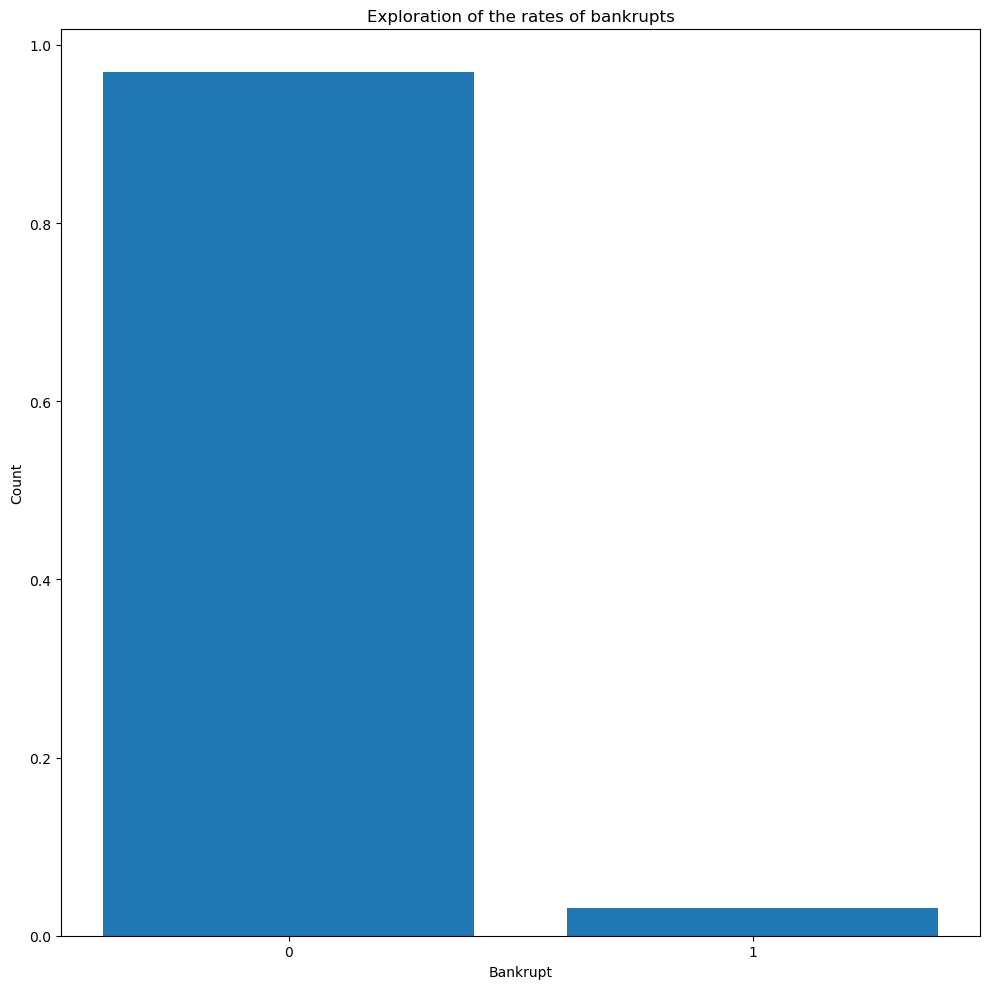

In [20]:
#A bar plot of this 
fig, ax = plt.subplots(figsize = (10,10))
ax.bar(bankrupt_rates.index, height = bankrupt_rates.values)
ax.set_xticks([0, 1])
ax.set_title('Exploration of the rates of bankrupts')
ax.set_xlabel('Bankrupt')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

**From this exploration :**

There is class imbalance in the target column because the rate of non-bankrupt values is around 96% which much higher than bankrupt rates which valued with around 3%

**Step 2: Dviding the model into training and testing set**

In [21]:
#Dropping any null observations
tiwan_df = tiwan_df.copy().dropna()
tiwan_df

,id,bankrupt,_,_,_,_,_,_,_,_,...,_,_,_,_,_,_,_,_,_,_
0,1,True,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,2,True,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,3,True,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,4,True,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,5,True,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6132,6812,False,0.518062,0.567870,0.565823,0.612736,0.612527,0.999140,0.797745,0.809603,...,0.815844,0.003725,0.622780,0.612735,0.841355,0.277588,0.026864,0.565483,1,0.043531
6133,6816,False,0.475162,0.538269,0.524172,0.598308,0.598308,0.998992,0.797414,0.809327,...,0.799748,0.001959,0.623931,0.598306,0.840306,0.278132,0.027009,0.566018,1,0.038284
6134,6817,False,0.472725,0.533744,0.520638,0.610444,0.610213,0.998984,0.797401,0.809317,...,0.797778,0.002840,0.624156,0.610441,0.840138,0.275789,0.026791,0.565158,1,0.097649
6135,6818,False,0.506264,0.559911,0.554045,0.607850,0.607850,0.999074,0.797500,0.809399,...,0.811808,0.002837,0.623957,0.607846,0.841084,0.277547,0.026822,0.565302,1,0.044009


In [22]:
#Defining the feature matrix and target vactor in this project
target = 'bankrupt'
X = tiwan_df.drop(columns=['id', target])
y = tiwan_df[target]

X.shape, y.shape

((6137, 95), (6137,))

In [23]:
#Dividing the data into training and testing set 
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify = y, test_size = 0.25, random_state = 42)
X_train.shape, X_test.shape

((4602, 95), (1535, 95))

In [24]:
#Defining the train rate and test rate
train_rate = y_train.mean()
test_rate = y_test.mean()
print(f"Train Rate: {train_rate:.2f}")
print(f"Test Rate: {test_rate:.2f}")

Train Rate: 0.03
Test Rate: 0.03


**Step 3: Training models and evaluating metrics**

First Part: Logistic Regression

In [25]:
#Instantiating the logistic regression model
log_reg_model = LogisticRegression(max_iter = 1000, solver = 'lbfgs')
#Training the model
log_reg_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [26]:
#Calculate prediction and probabilities
y_pred_log_reg = log_reg_model.predict(X_test)
y_proba_log_reg = log_reg_model.predict_proba(X_test)[:, 1]

In [27]:
#Initializing the logistic regression with MinMaxScaler (X - min(X) / max(X) - min(X))
log_reg_model_scaled = Pipeline([('scaler', MinMaxScaler()), ('model', LogisticRegression(max_iter = 1000, solver = 'lbfgs'))])
#Training the model
log_reg_model_scaled.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,feature_range,"(0, ...)"
,copy,True
,clip,False
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [28]:
#Calculating the prediction and probabilities
y_pred_log_reg_scaled = log_reg_model_scaled.predict(X_test)
y_proba_log_reg_scaled = log_reg_model_scaled.predict_proba(X_test)[:, 1]

In [29]:
#Defining the function of calculating metrics
def evaluate_metrics(name, y_true, y_pred, y_proba):
    """
    The function is for calculating metrics (accuracy, precision, recall, f1 score, AUC score, average precision score)
    Parameters: 
    name: model name
    y_true: true labels
    y_pred: predicting labels
    y_proba: predicting probabilities for class 1

    Returns: dictionary of metrics
    """
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division = 0),
        "Recall": recall_score(y_true, y_pred, zero_division = 0),
        "F1": f1_score(y_true, y_pred, zero_division = 0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba)
    }

In [30]:
#Initializing the comparison for the model with scaling and without scaling
log_reg_comp = [
    evaluate_metrics("LogisticRegressionNotScaled", y_test, y_pred_log_reg, y_proba_log_reg),
    evaluate_metrics("LogisticRegressionWithMinMaxScaler", y_test, y_pred_log_reg_scaled, y_proba_log_reg_scaled)
]
results = pd.DataFrame(log_reg_comp).set_index("Model")
results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
LogisticRegressionNotScaled,0.963518,0.000000,0.000000,0.000000,0.594219,0.038210
LogisticRegressionWithMinMaxScaler,0.971987,0.777778,0.145833,0.245614,0.900205,0.316805


**Results Insight**

The model with MinMaxScaler is better than not scaled and strong evidences are:
1. the accuracy score of this is a bit better than not scaled one
2. the AUC score for the scaled one is obviously better than not scaled one
3. The scaled ones catches some true values significantly from the precision, recall, and f1-score in contrast to the not-scaled one


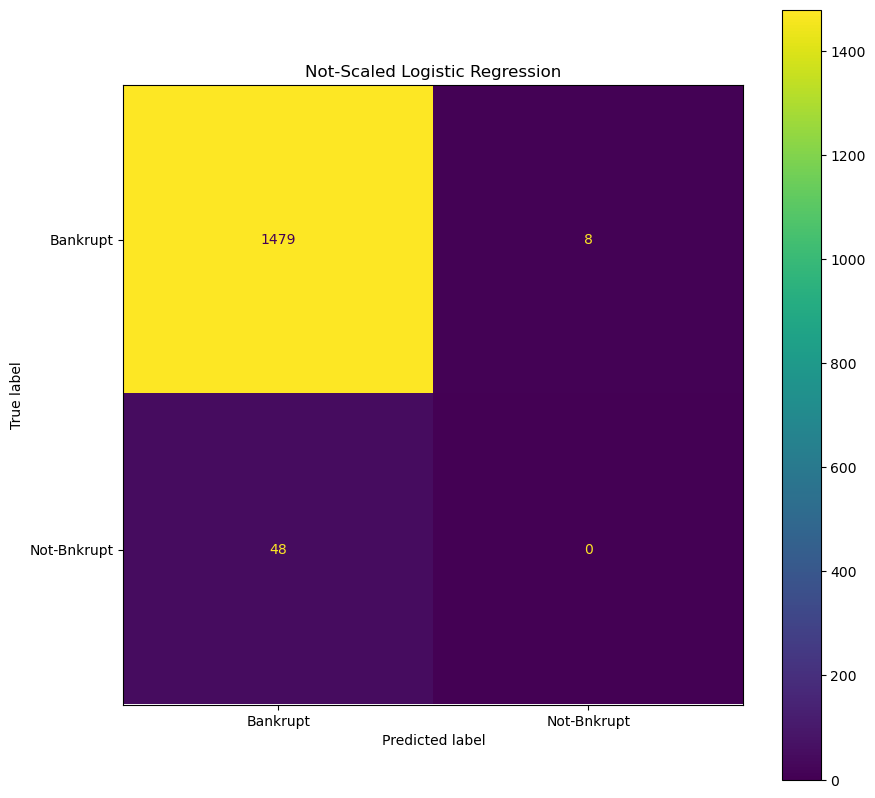

In [31]:
#Getting the confusion matrix of the not-scaled logistic regression model
cm_not_scaled = confusion_matrix(y_test, y_pred_log_reg)
fig, ax = plt.subplots(figsize = (10,10))
disp_not = ConfusionMatrixDisplay(cm_not_scaled, display_labels = ['Bankrupt', 'Not-Bnkrupt'])
disp_not.plot(ax = ax)
ax.set_title('Not-Scaled Logistic Regression')
plt.show()

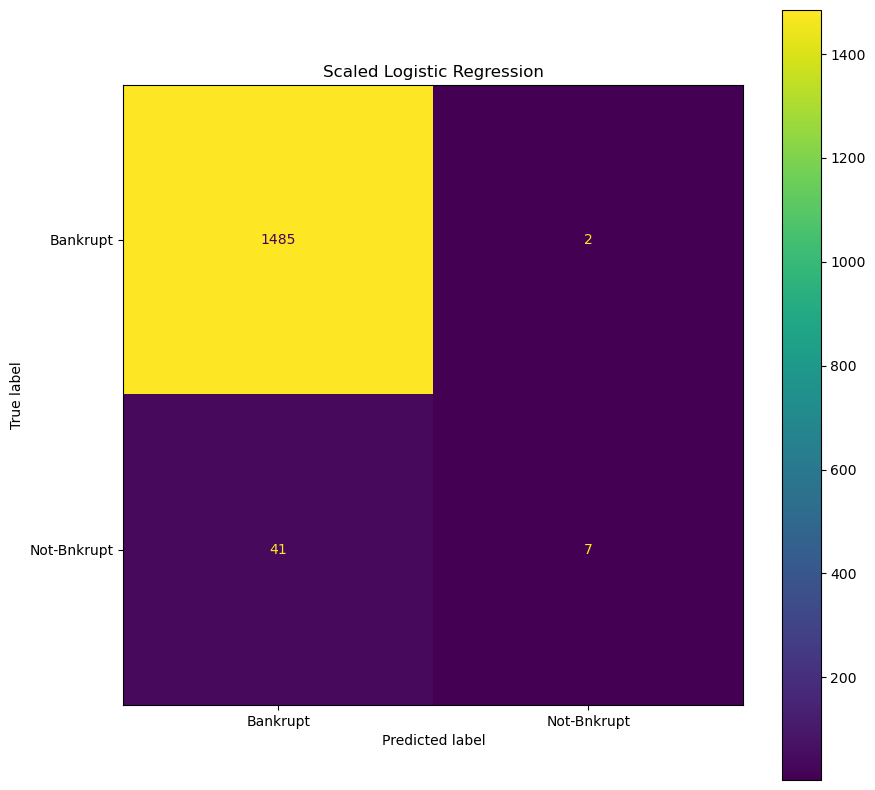

In [32]:
#Getting the confusion matrix of the scaled logistic regression model
cm_scaled = confusion_matrix(y_test, y_pred_log_reg_scaled)
fig, ax = plt.subplots(figsize = (10,10))
disp = ConfusionMatrixDisplay(cm_scaled, display_labels = ['Bankrupt', 'Not-Bnkrupt'])
disp.plot(ax = ax)
ax.set_title('Scaled Logistic Regression')
plt.show()

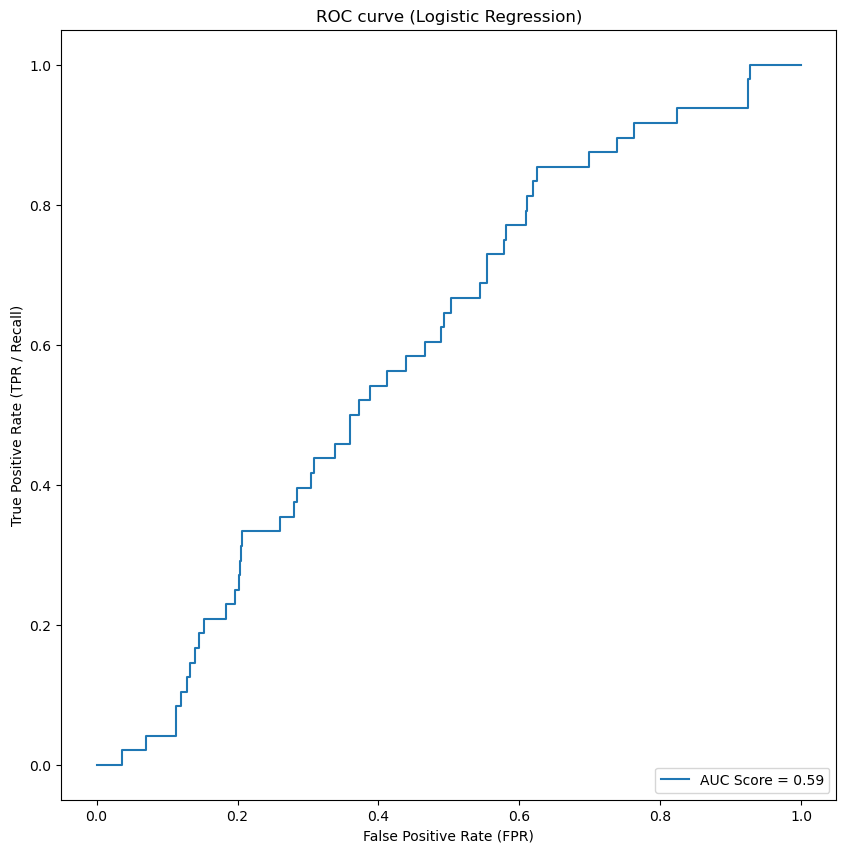

In [33]:
#Plot ROC Curve for the logistic regresstion model
fpr, tpr, thresholds = roc_curve(y_test, y_proba_log_reg)
fig, ax = plt.subplots(figsize = (10,10))
ax.plot(fpr, tpr, label = f"AUC Score = {roc_auc_score(y_test, y_proba_log_reg):.2f}")
ax.set_title("ROC curve (Logistic Regression)")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (TPR / Recall)")
ax.legend(loc="lower right")
plt.show()

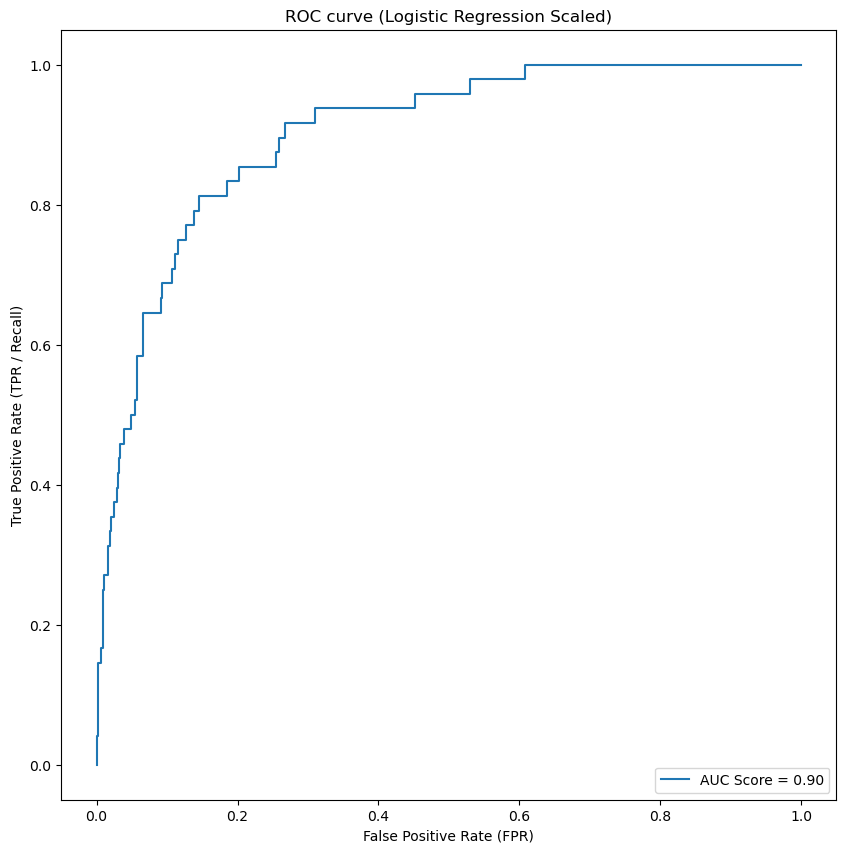

In [34]:
#Plot ROC Curve for the scaled logistic regresstion model
fpr, tpr, thresholds = roc_curve(y_test, y_proba_log_reg_scaled)
fig, ax = plt.subplots(figsize = (10,10))
ax.plot(fpr, tpr, label = f"AUC Score = {roc_auc_score(y_test, y_proba_log_reg_scaled):.2f}")
ax.set_title("ROC curve (Logistic Regression Scaled)")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (TPR / Recall)")
ax.legend(loc="lower right")
plt.show()

The scaled one is better according to AUC score unlike the not-scaled one which tends to be like a random classifier

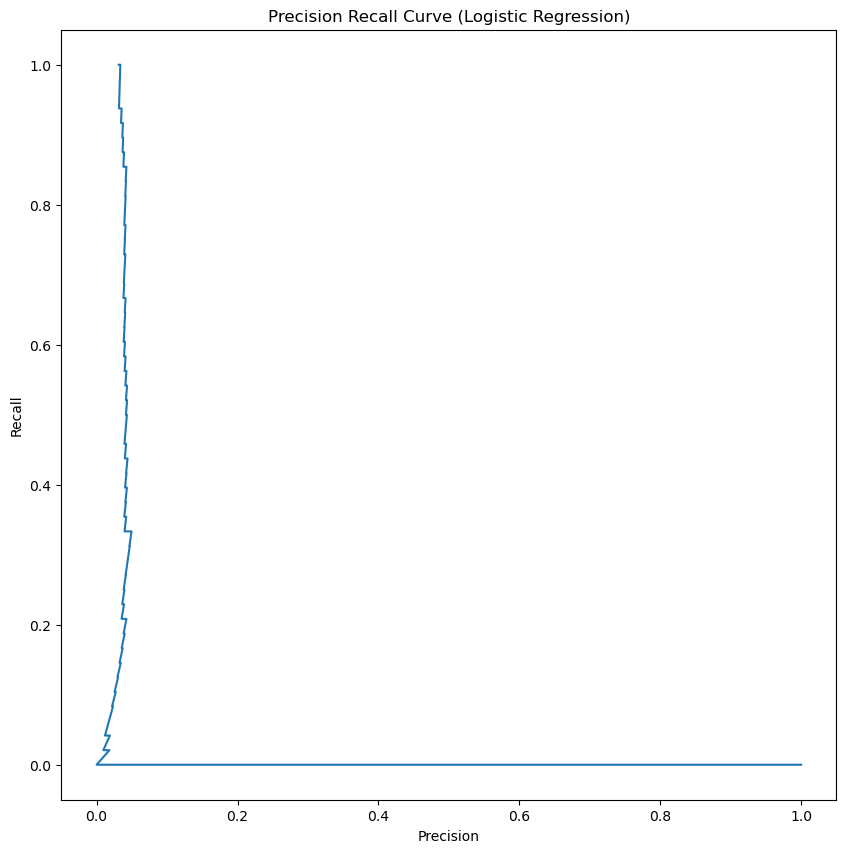

In [35]:
#Plotting the precision-recall curve for the logistic regression model
prec, rec, thresholds = precision_recall_curve(y_test, y_proba_log_reg)
fig, ax = plt.subplots(figsize = (10,10))
ax.plot(prec, rec)
ax.set_title("Precision Recall Curve (Logistic Regression)")
ax.set_xlabel("Precision")
ax.set_ylabel("Recall")
plt.show()

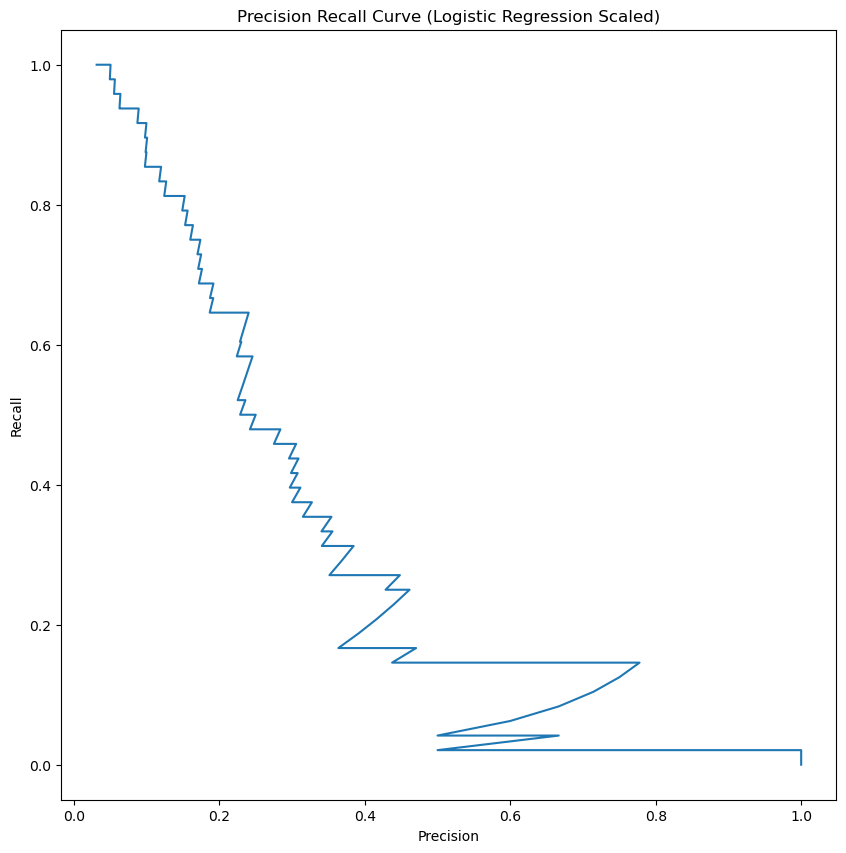

In [36]:
#Plotting the precision-recall curve for the scaled logistic regression model
prec, rec, thresholds = precision_recall_curve(y_test, y_proba_log_reg_scaled)
fig, ax = plt.subplots(figsize = (10,10))
ax.plot(prec, rec)
ax.set_title("Precision Recall Curve (Logistic Regression Scaled)")
ax.set_xlabel("Precision")
ax.set_ylabel("Recall")
plt.show()

Scaled PR Curve:
Scaled curves maintain high precision across recall thresholds.

Unscaled PR Curve:
Unscaled curves instantly drop precision, resembling random guessing.

Second Part: Random Forest Classification

In [38]:
#Initializing the random forest model
rf_model = Pipeline([('impute', SimpleImputer(strategy = 'median'))
                    , ('classifier', RandomForestClassifier(n_estimators = 300, random_state = 42, n_jobs = -1, class_weight = 'balanced'))])
#Training the model
rf_model.fit(X_train, y_train)

,steps,"[('impute', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,n_estimators,300


In [39]:
#Calculating the prediction and probabilities
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [40]:
#Trying the over sampling on the training data
ros = RandomOverSampler(random_state = 42)
X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

In [41]:
#Initializing another model of random forst classification
rf_model_sample = Pipeline([
    ('impute', SimpleImputer(strategy = 'median')),
    ('classifier', RandomForestClassifier(n_estimators = 300, random_state = 42, n_jobs = -1, class_weight = 'balanced'))
])
#Training this model using over-sampled training data
rf_model_sample.fit(X_train_over, y_train_over)

,steps,"[('impute', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,n_estimators,300


In [42]:
#Calculating prediction and probabilities for resampled training model
y_pred_resample = rf_model_sample.predict(X_test)
y_pred_proba_resample = rf_model_sample.predict_proba(X_test)[:, 1]

In [44]:
#Computing metrics for the model and its resampled 
rf_rows = [
    evaluate_metrics("RandomForestModel", y_test, rf_pred, rf_prob),
    evaluate_metrics("RandomForestModelResampled", y_test, y_pred_resample, y_pred_proba_resample)
]

rf_results = pd.DataFrame(rf_rows).set_index("Model")
rf_results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
RandomForestModel,0.967427,0.400000,0.083333,0.137931,0.908961,0.270065
RandomForestModelResampled,0.960261,0.275862,0.166667,0.207792,0.922488,0.262020


There are some differences on the random forest model and its resampled:
1. From the accuracy, the ordinary model is a bit higher than the resampled one and the precision too.
2. From the recall, F1 and ROC-AUC score, the resampled one is higher
 
Which we can conclude that resampling impproves minority class prediction at the cost of precision

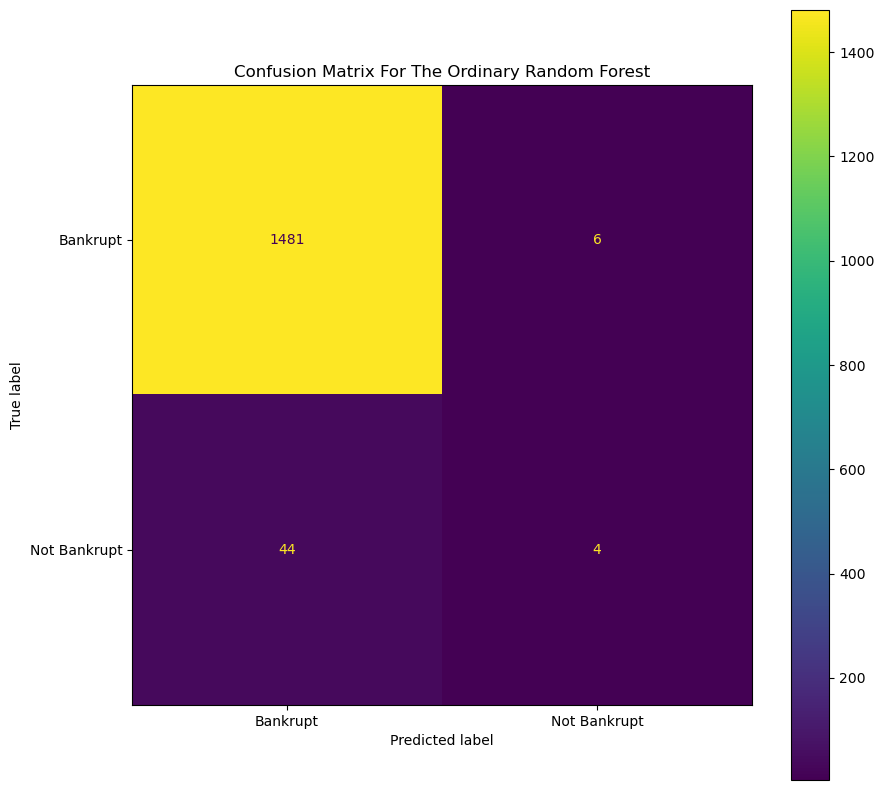

              precision    recall  f1-score   support

       False       0.97      1.00      0.98      1487
        True       0.40      0.08      0.14        48

    accuracy                           0.97      1535
   macro avg       0.69      0.54      0.56      1535
weighted avg       0.95      0.97      0.96      1535



In [46]:
#Generating the confusion matrix and classification report for the ordinary model
cm = confusion_matrix(y_test, rf_pred)
fig, ax = plt.subplots(figsize = (10,10))
disp = ConfusionMatrixDisplay(cm, display_labels = ['Bankrupt', 'Not Bankrupt'])
disp.plot(ax = ax)
ax.set_title('Confusion Matrix For The Ordinary Random Forest')
plt.show()

#Classification Report
print(classification_report(y_test, rf_pred, zero_division = 0))

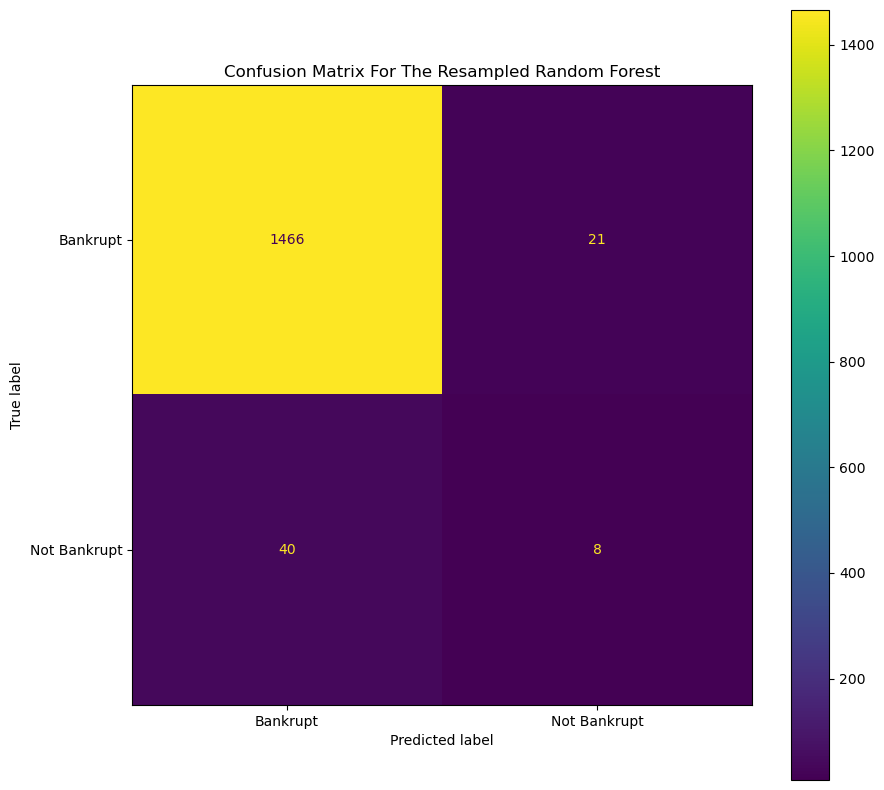

              precision    recall  f1-score   support

       False       0.97      0.99      0.98      1487
        True       0.28      0.17      0.21        48

    accuracy                           0.96      1535
   macro avg       0.62      0.58      0.59      1535
weighted avg       0.95      0.96      0.96      1535



In [59]:
#Generating the confusion matrix and classification report for the ordinary model
cm = confusion_matrix(y_test, y_pred_resample)
fig, ax = plt.subplots(figsize = (10,10))
disp = ConfusionMatrixDisplay(cm, display_labels = ['Bankrupt', 'Not Bankrupt'])
disp.plot(ax = ax)
ax.set_title('Confusion Matrix For The Resampled Random Forest')
plt.show()

#Classification Report
print(classification_report(y_test, y_pred_resample, zero_division = 0))

In [51]:
#Running 5-fold cross validation on training data
scores = cross_val_score(rf_model, X_train, y_train, cv = 5, scoring = 'roc_auc')
scores, scores.mean(), scores.std()

(array([0.94512525, 0.97962734, 0.93373639, 0.91449792, 0.92522822]),
 np.float64(0.9396430228191477),
 np.float64(0.022377450987169655))

On the ordinary model, the accuracy is well but the variation is low

In [52]:
#Running 5-fold cross validation on training data
scores_sample = cross_val_score(rf_model_sample, X_train_over, y_train_over, cv = 5, scoring = 'roc_auc')
scores_sample, scores_sample.mean(), scores_sample.std()

(array([1., 1., 1., 1., 1.]), np.float64(1.0), np.float64(0.0))

On the resampled data, the scores are approximates from close to 1 to 1.0 and from close to 0 to 0.0

In [54]:
#Running GridSearchCV on the ordinary random forest only so that we can define the best one 

#Defining the parameter grid for a pipeline
param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [None, 8, 10],
    "classifier__min_samples_leaf": [1, 5, 10]
}

grid = GridSearchCV(rf_model, param_grid = param_grid, scoring = 'roc_auc', cv = 3, n_jobs = -1)

#Training
grid.fit(X_train, y_train)

#Defining the best score and the best params
grid.best_score_ , grid.best_params_

(np.float64(0.9524440228360106),
 {'classifier__max_depth': 8,
  'classifier__min_samples_leaf': 10,
  'classifier__n_estimators': 400})

In [55]:
#Initializing the final best model
best_rf_model = grid.best_estimator_

#Training the model
best_rf_model.fit(X_train, y_train)

#Calculating the prediction and probabilities
rf_best_pred = best_rf_model.predict(X_test)
rf_best_predict_proba = best_rf_model.predict_proba(X_test)[:, 1]

Third Part: Gradient Boosting Calassification

In [56]:
#Initializing the gradient boosting model
gb_model = Pipeline([
    ('impute', SimpleImputer(strategy = 'median')),
    ('classifier', GradientBoostingClassifier(random_state = 42))
])

#Training the model
gb_model.fit(X_train, y_train)

#Calculating the prediction and prpbabilities
gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, gb_pred, zero_division = 0))

              precision    recall  f1-score   support

       False       0.98      0.99      0.98      1487
        True       0.52      0.31      0.39        48

    accuracy                           0.97      1535
   macro avg       0.75      0.65      0.69      1535
weighted avg       0.96      0.97      0.97      1535



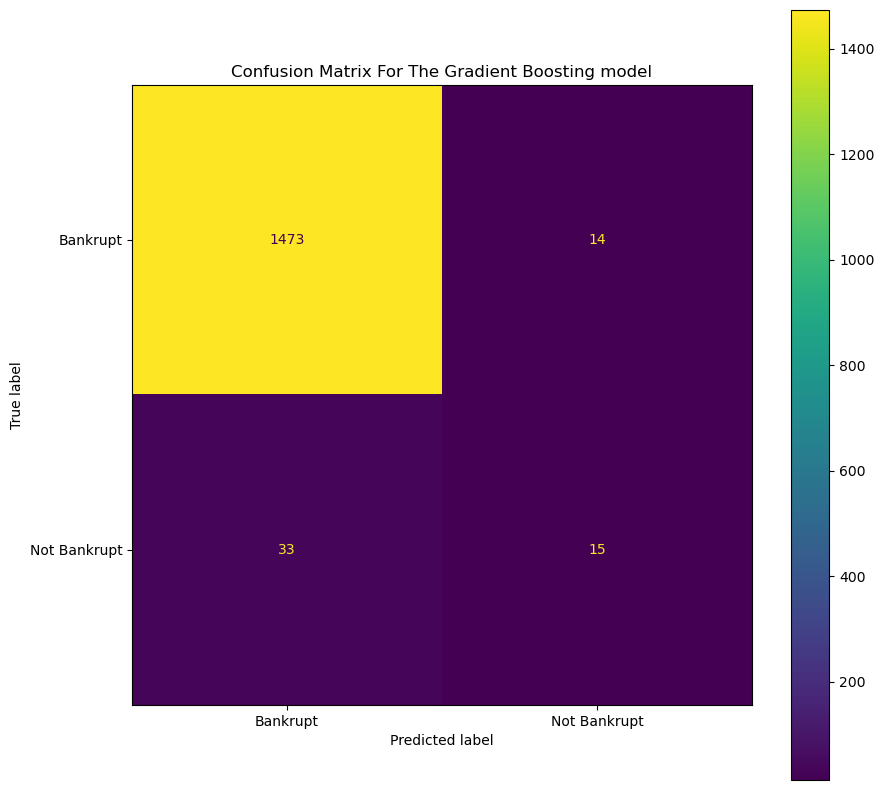

              precision    recall  f1-score   support

       False       0.98      0.99      0.98      1487
        True       0.52      0.31      0.39        48

    accuracy                           0.97      1535
   macro avg       0.75      0.65      0.69      1535
weighted avg       0.96      0.97      0.97      1535



In [60]:
#Generating the confusion matrix and classification report for the ordinary model
cm = confusion_matrix(y_test, gb_pred)
fig, ax = plt.subplots(figsize = (10,10))
disp = ConfusionMatrixDisplay(cm, display_labels = ['Bankrupt', 'Not Bankrupt'])
disp.plot(ax = ax)
ax.set_title('Confusion Matrix For The Gradient Boosting model')
plt.show()

#Classification Report
print(classification_report(y_test, gb_pred, zero_division = 0))

In [57]:
#Initializing the grid search cross validation to find the best gradient boosting model


#Parameter Grid
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2,3],
    "classifier__subsample": [1.0, 0.8],
}

#Initializing the grid
gb_grid = GridSearchCV(gb_model, param_grid = param_grid, scoring = 'roc_auc', cv = 3, n_jobs = -1)

#Training the grid
gb_grid.fit(X_train, y_train)

#Defining the best score and best parameters
gb_grid.best_score_ , gb_grid.best_params_

(np.float64(0.9425125848219299),
 {'classifier__learning_rate': 0.05,
  'classifier__max_depth': 2,
  'classifier__n_estimators': 100,
  'classifier__subsample': 1.0})

In [58]:
#Defining the best gradient boosting model, training it and calculating the prediction and probabilities
best_gb_model = gb_grid.best_estimator_

#Training
best_gb_model.fit(X_train, y_train)

#Predicting the model and getting probabilities
y_gb_best_pred = best_gb_model.predict(X_test)
y_gb_best_prob = best_gb_model.predict_proba(X_test)[:, 1]

The comparison between the scaled logistic regression model, random forest classifier and the gradient boosting classifier

In [65]:
final_rows = [
    evaluate_metrics("LogisticRegressionScaledModel", y_test, y_pred_log_reg_scaled, y_proba_log_reg_scaled),
    evaluate_metrics("RandomForestModel", y_test, rf_pred, rf_prob),
    evaluate_metrics("GradientBoostingClassifier", y_test, gb_pred, gb_prob)
]

final_results = pd.DataFrame(final_rows).set_index("Model")
final_results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
LogisticRegressionScaledModel,0.971987,0.777778,0.145833,0.245614,0.900205,0.316805
RandomForestModel,0.967427,0.400000,0.083333,0.137931,0.908961,0.270065
GradientBoostingClassifier,0.969381,0.517241,0.312500,0.389610,0.925563,0.424240


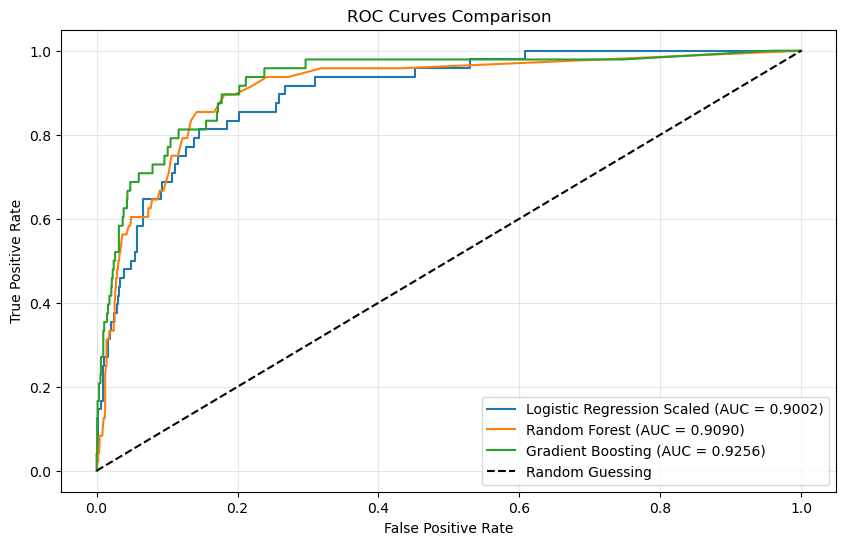

In [66]:
# Calculate False Positive Rates (FPR) and True Positive Rates (TPR) for each model
fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_log_reg_scaled)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_prob)

# Extract ROC-AUC scores for the legend (or recalculate them)
auc_log = roc_auc_score(y_test, y_proba_log_reg_scaled)
auc_rf = roc_auc_score(y_test, rf_prob)
auc_gb = roc_auc_score(y_test, gb_prob)

# Plotting
plt.figure(figsize=(10, 6))

plt.plot(fpr_log, tpr_log, label=f'Logistic Regression Scaled (AUC = {auc_log:.4f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})')
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_gb:.4f})')

# Plot the random guessing baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')

# Formatting the plot
plt.title('ROC Curves Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.show()

From these final results: 
We conclude that the gradient boosting model is the best for predicting the bankruptcy in Tiwan 